# HW5 : 전처리 재현 + 질문 셋

입력 : `sales_data.csv` (수업과 같은 파일)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform

# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
         "Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

## 단계 ① 읽고 날짜 세 칸을 날짜로

In [2]:
df = pd.read_csv("sales_data.csv")

dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])

df.shape

(1030, 14)

결측치 세 칸(`customer_age` 51 · `satisfaction` 30 · `delivery_date` 5)은 수업과 같이 **그대로 둔다**. 평균으로 채우면 없던 봉우리가 생기고, 계산할 때는 pandas 가 빈칸을 알아서 건너뛴다.

In [3]:
df.isnull().sum()

order_date          0
shipping_date       0
delivery_date       5
region              0
category            0
product_id          0
quantity            0
unit_price          0
customer_id         0
customer_age       51
customer_gender     0
satisfaction       30
status              0
total_sales         0
dtype: int64

## 단계 ② 중복 행 제거

In [4]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


## 단계 ③ 수량 > 100 인 줄의 수량을 금액 ÷ 단가로 복원

금액 ÷ 단가가 22 줄 모두 정수로 떨어지므로 틀린 칸은 수량이다.

In [5]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


## 단계 ④ date_error 추가, sales_clean.csv 저장

도착일 < 배송일 인 줄은 어느 날짜가 틀렸는지 알려 주는 칸이 없으므로 고치지 않고 표시만 한다.

In [6]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
print(df["date_error"].sum(), "건")

df.to_csv("sales_clean.csv", index=False)
df.shape

147 건


(1004, 15)

## 단계 ⑤ 배송 기간 (도착일 − 배송일) 은 보통 며칠인가

줄 수 : 852  (도착일이 빈 5 줄은 자동으로 빠짐)
평균 : 22.05 일  중앙값 : 2.0 일


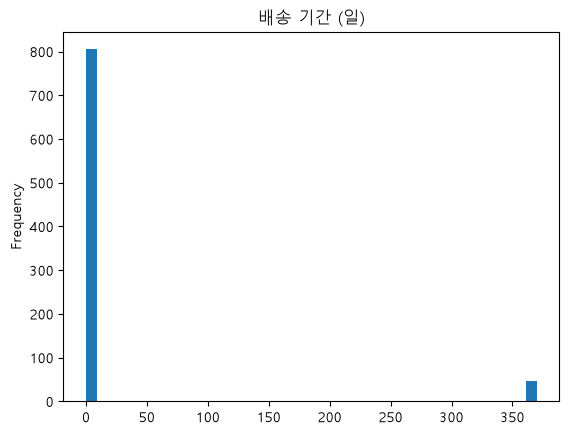

In [7]:
ok = df[~df["date_error"]]
days = (ok["delivery_date"] - ok["shipping_date"]).dt.days
print("줄 수 :", days.count(), " (도착일이 빈 5 줄은 자동으로 빠짐)")
print("평균 :", round(days.mean(), 2), "일  중앙값 :", days.median(), "일")

days.plot.hist(bins=40, title="배송 기간 (일)")
plt.show()

평균 22.05일과 중앙값 2일이 크게 다르다. 히스토그램 오른쪽 끝(360일 근처)에 덩어리가 있다. 들여다본다.

In [8]:
big = days[days > 300]
print("300일 넘는 줄 :", len(big), "건,", big.min(), "~", big.max(), "일")
ok.loc[big.index, ["shipping_date", "delivery_date", "status"]].head()

300일 넘는 줄 : 47 건, 364.0 ~ 370.0 일


,shipping_date,delivery_date,status
11,2023-01-15,2024-01-15,배송완료
20,2023-01-23,2024-01-27,배송완료
29,2023-02-03,2024-02-03,배송완료
41,2023-02-14,2024-02-17,배송완료
68,2023-03-14,2024-03-12,배송완료


In [9]:
# 도착일에서 1년을 빼 보면
minus1 = (ok.loc[big.index, "delivery_date"] - pd.DateOffset(years=1) - ok.loc[big.index, "shipping_date"]).dt.days
print("1년을 뺀 일수 :", sorted(int(d) for d in minus1.unique()))
print("그래도 음수인 줄 :", (minus1 < 0).sum(), "건")

1년을 뺀 일수 : [-2, -1, 0, 1, 2, 3, 4, 5]
그래도 음수인 줄 : 7 건


47 건 모두 364 ~ 370 일, 곧 「1년 + 0 ~ 5 일」이다. 도착 연도만 한 해 뒤로 잘못 적힌 것으로 보인다.

다만 1년을 빼면 7 건이 음수가 되어(도착일이 배송일보다 빠름) 「연도만 틀렸다」는 근거가 모든 줄에 맞지는 않는다. 그래서 **복원하지 않고 배송 기간 계산에서만 뺀다.**

뺀 뒤 줄 수 : 805
평균 : 1.93 일  중앙값 : 2.0 일


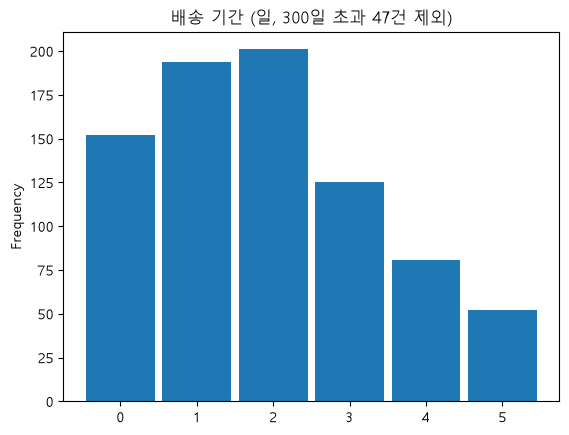

In [10]:
days_ok = days[days <= 300]
print("뺀 뒤 줄 수 :", days_ok.count())
print("평균 :", round(days_ok.mean(), 2), "일  중앙값 :", days_ok.median(), "일")

days_ok.plot.hist(bins=range(0, 7), rwidth=0.9, align="left", title="배송 기간 (일, 300일 초과 47건 제외)")
plt.show()

**답** : 보통 배송 기간은 **2일**(중앙값)이다. 300일 초과 47건을 빼면 평균 1.93일 · 중앙값 2일로 거의 같아지고, 0 ~ 5일 안에 모두 들어간다.

평균(22.05일)과 중앙값(2일)이 크게 달랐던 이유는 도착 연도가 한 해 뒤로 적힌 것으로 보이는 364 ~ 370일짜리 47건이 평균만 끌어올렸기 때문이다. 1년을 빼면 7건이 음수가 되어 복원 근거가 부족하므로 이 47건은 배송 기간 계산에서만 제외했다.

## 단계 ⑥ 만족도가 낮을수록 반품이 많은가

전체 반품 비율 : 8.6 %
satisfaction
1.0     7.6
2.0    12.0
3.0     7.8
4.0     8.7
5.0     6.9
Name: status, dtype: float64


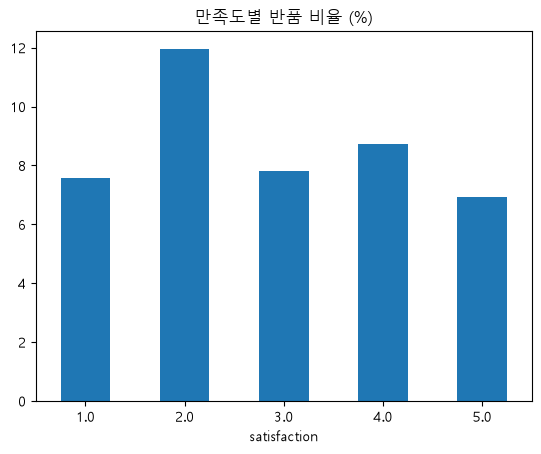

In [11]:
rate = (df["status"] == "반품").groupby(df["satisfaction"]).mean() * 100
print("전체 반품 비율 :", round((df["status"] == "반품").mean() * 100, 1), "%")
print(rate.round(1))

rate.plot.bar(title="만족도별 반품 비율 (%)", rot=0)
plt.show()

**답** : **아니다.** 만족도 1점의 반품 비율은 7.6%로 5점(6.9%)과 거의 같고, 가장 높은 것은 2점(12.0%)이다.

3점 7.8%, 4점 8.7%까지 만족도가 낮아질수록 반품이 늘어나는 순서가 보이지 않으며, 다섯 값 모두 전체 평균 8.6% 근처에 있다. (만족도가 빈 30줄은 제외)

## 단계 ⑦ 카테고리 매출 1위의 이유는 건수 · 단가 · 수량 중 무엇인가

In [12]:
table = df.groupby("category").agg(
    건수=("total_sales", "size"),
    매출합_억=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean"),
)
table["매출합_억"] = table["매출합_억"] / 1e8
table.sort_values("매출합_억", ascending=False).round(1)

,건수,매출합_억,평균단가,평균수량
category,,,,
가구,213,28.4,257322.9,51.0
식품,210,25.1,255232.9,47.3
전자제품,207,24.7,249651.6,48.0
도서,204,24.5,238500.6,49.5
의류,170,21.8,249447.2,51.6


**답** : 1위는 **가구**(28.4억)이다. 5위 의류(21.8억)와 비교하면 평균 단가는 25.7만 원 vs 24.9만 원, 평균 수량은 51.0 vs 51.6개로 거의 같고, **건수가 213 vs 170**으로 크게 다르다.

2위 식품(25.1억)과는 건수(213 vs 210)와 단가는 비슷하고 평균 수량이 51.0 vs 47.3개로 조금 많다. 세 칸 모두 가구가 조금씩 높지만, 순위 차이를 가장 크게 만드는 칸은 **건수**다.